# Supplementary Fig. 5d: decoding performance of the CEBRA model, evoked regime

**author**: laquitainesteeve@gmail.com

**purpose**: reproduce panel d of Supplementary Fig. 5: precision and recall of a model that uses both the full spike waveforms and the quality metrics to curate the 'good' units (agreement score of at least 0.8 with a ground truth neuron) amongst the single-units sorted by Kilosort4 from the biophysical simulation of the evoked regime. Each black dot is one cross-validated fold, orange dots are the medians over 100 folds. The red dashed line marks 0.5. Source data and svg are saved in figures/8_source_data/supp_fig5d/.

**prerequisites**: the `spikebias` environment with `cebra==0.4.0` and `scikit-learn==1.5.2` (the versions pinned in `envs/cebraspike.txt`; cebra 0.4.0 does not work with scikit-learn 1.6 and later) and `literate-dataclasses`; a GPU makes the training faster (about 10 minutes for 100 folds on an RTX 5090).

**method (as in the paper's notebook supp_fig5_C_curation_cebraspike_NS.ipynb)**
* dataset: the sorted single-units (first 10 minutes) with at least 25 spikes; for each unit the 25 first spike waveforms (+/- 3 ms around the peak, on the site with the largest amplitude) are concatenated into one vector of 3,000 values (20 kHz), to which the 11 quality metrics of the unit are appended (`src/nodes/models/CebraSpike/dataloader.py`); units with missing metrics are dropped; label: 'good' (spike assignment bias containing 'good') or degraded ('merged + partial')
* quality metrics are computed on the first 10 minutes of the recording (the waveform extractor of the single-units is the one made by fig5e.ipynb)
* model: CEBRA (offset10-model, 3 output dimensions, cosine distance, supervised by the good/degraded label, 40 iterations, learning rate 0.001, batch size = number of columns of the dataset as in the paper's notebook) followed by a 20-nearest-neighbor classifier on the embeddings
* evaluation: 100 random splits (80% of the units of each class for training, 20% for testing; stratified), precision and recall on the test units

In [1]:
# SETUP PACKAGES
import os
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from matplotlib import pyplot as plt
warnings.simplefilter(action="ignore")

# SET PROJECT PATH
PROJ_PATH = "/home/steeve/steeve/epfl/code/spikebias"
os.chdir(PROJ_PATH)
from src.nodes.models.CebraSpike import dataloader as cs_dataloader
from src.nodes.models.CebraSpike.models import CebraSpike

# DATA: 10 minutes of the evoked regime sorted with Kilosort4
QUALITY_PATH = "dataset/01_intermediate/quality/sorting_quality.csv"
SORTING_PATH = "dataset/01_intermediate/sorting/npx_evoked/SortingKS4_10m"
GROUND_TRUTH_PATH = "dataset/00_raw/ground_truth_npx_evoked_10m"
WAVEFORMS_PATH = "dataset/01_intermediate/waveforms/npx_evoked/SortingKS4_10m_single_units"      # waveforms of the sorted single-units (first 10 minutes, see fig5f.ipynb)
EXP, SORTER = "E", "KS4"
MODEL_PATH = "models/cebra/evoked_40_iterations/"     # weights of the 100 cross-validated models (.pt) and folds.csv

# MODEL PARAMETERS
N_SPIKES = 25               # spikes per unit
INTERVAL_MS = 3             # waveform window: +/- 3 ms around the spike peak (120 samples at 20 kHz)
N_NEIGHBORS = 20            # k-nearest neighbor decoder
SEEDS = np.arange(0, 100, 1)

# FIGURE SETTINGS
plt.rcParams["font.family"] = "DejaVu Sans"   # the paper's figure was drawn without Arial (matplotlib default font)
plt.rcParams["font.size"] = 6  # 5-7 with Nature neuroscience as reference
plt.rcParams["lines.linewidth"] = 0.5
plt.rcParams["axes.linewidth"] = 0.5
plt.rcParams["axes.spines.top"] = False
plt.rcParams["xtick.major.width"] = 0.5
plt.rcParams["ytick.major.width"] = 0.5
plt.rcParams["xtick.major.size"] = 3.5 * 1.1
plt.rcParams["ytick.major.size"] = 3.5 * 1.1
savefig_cfg = {"transparent": True, "dpi": 300}

In [ ]:
# Nature figure guidelines for every saved figure: Arial, 5-7 pt, editable text, images of at least 300 dpi, a .pdf next to each .svg
import os, sys
sys.path.insert(0, os.getcwd())     # the repository (the notebook moved there above)
from src.nodes import figure_style
figure_style.apply()

## Load the dataset

In [2]:
%%time

data_cs = cs_dataloader.load_dataset(qpath=QUALITY_PATH, sorting_path=SORTING_PATH, sortingtrue_path=GROUND_TRUTH_PATH, study_path=WAVEFORMS_PATH, study_singleu_path=WAVEFORMS_PATH,
                                     exp=EXP, sorter=SORTER, n_site=384, num_spikes=N_SPIKES, interval_ms=INTERVAL_MS, downsampling=1, load_we_if_exists=True, load_amp_if_exists=True, load_qmetrics_if_exists=False)
dataset = data_cs["dataset"]
print("units:", dataset["data"].shape[0], "| good:", int(dataset["label"].sum()), "| features:", dataset["data"].shape[1])

2026-11-03 09:32:49,884 - root - dataloader.py - load_dataset - INFO - Starting loading dataset..


2026-11-03 09:32:49,884 - root - dataloader.py - load_dataset - INFO - Computing sorted unit quality metrics..


  0%|          | 0/408 [00:00<?, ?it/s]

****************** Analysing data completion ***************
quality metrics are: Index(['amplitude_cutoff', 'firing_range', 'firing_rate',
       'isi_violations_ratio', 'presence_ratio', 'rp_contamination',
       'rp_violations', 'sd_ratio', 'snr', 'silhouette', 'mad_ratio'],
      dtype='object')
Data completion: amplitude_cutoff        408
firing_range            408
firing_rate             408
isi_violations_ratio    408
presence_ratio          408
rp_contamination        408
rp_violations           408
sd_ratio                408
snr                     408
silhouette              407
mad_ratio               408
dtype: int64
Dropping units with missing metrics...
nb of units before curation: 408
nb of units after curation: 407
2026-11-03 09:33:56,280 - root - dataloader.py - load_dataset - INFO - Computed quality metrics


Recording sampling frequency: 20000.0


ex. dataset shape (L4): (36, 3000)
ex. label shape (L4): (36,)

unit sample size:

L1:  0 units
L23:  7 units
L4:  36 units
L5:  300 units
L6:  64 units

********** DATASET STATS **********:


unit count:

l1: 0
l23: 6
l4: 36
l5: 300
l6: 64
units: 406 | good: 105 | features: 3011
CPU times: user 1min 1s, sys: 19.8 s, total: 1min 20s
Wall time: 1min 26s


## Train and evaluate the CEBRA model (about 10 minutes)

In [3]:
%%time

torch.manual_seed(0)       # reproducibility
csmodel = CebraSpike(cfg={
    "model_architecture": "offset10-model",   # receptive field of size 10
    "distance": "cosine",                     # adapted to contrastive learning
    "batch_size": dataset["data"].shape[1],
    "temperature_mode": "auto",
    "learning_rate": 0.001,
    "max_iterations": 40,
    "conditional": "time_delta",
    "time_offsets": 10,
    "output_dimension": 3,
    "device": "cuda_if_available",
    "verbose": False})
os.makedirs(MODEL_PATH, exist_ok=True)
results = csmodel.evaluate(dataset, MODEL_PATH, is_train=True, seeds=SEEDS, n_neighbors=N_NEIGHBORS)
stats_ = results["metric_stats"]
print(f"precision median {stats_['precision_median']:.3f} (95% CI {stats_['precision_ci95']:.3f}), recall median {stats_['recall_median']:.3f} (95% CI {stats_['recall_ci95']:.3f})")

precision median 0.538 (95% CI 0.016), recall median 0.905 (95% CI 0.021)
CPU times: user 1min 33s, sys: 297 ms, total: 1min 33s
Wall time: 1min 28s


## Source data: precision and recall of each fold

In [4]:
df = pd.DataFrame({"fold": SEEDS, "precision": [m["precision"] for m in results["metric_data"]], "recall": [m["recall"] for m in results["metric_data"]]})
display(df[["precision", "recall"]].agg(["median", "count"]))

,precision,recall
median,0.538462,0.904762
count,100.000000,100.000000


## Plot, same as the paper's panel c

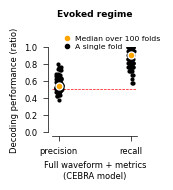

In [5]:
def plot_source_data(df: pd.DataFrame, title="Evoked regime"):
    """Precision and recall of the model on the test units of each cross-validated fold (black dots); median and 95% CI over folds (orange); red dashed line: 0.5"""

    np.random.seed(0)     # the horizontal jitter of the dots is random: fix it so that every plot is identical
    fig, ax = plt.subplots(1, 1, figsize=(1.1, 1.1))
    sns.stripplot(ax=ax, data=df[["precision", "recall"]], jitter=0.04, color="k", size=3)
    for x, col in enumerate(["precision", "recall"]):
        ax.errorbar(x=x, y=np.nanmedian(df[col]), yerr=1.96 * np.std(df[col]) / np.sqrt(len(df[col])), marker="o", color="orange", markeredgecolor="w", markersize=5, zorder=np.inf)
    ax.axhline(0.5, color="r", linestyle="--", linewidth=0.5, zorder=0)

    # disconnect axes (R style)
    ax.spines[["right", "top"]].set_visible(False)
    ax.spines["bottom"].set_position(("axes", -0.05))
    ax.yaxis.set_ticks_position("left")
    ax.spines["left"].set_position(("axes", -0.05))
    ax.set_ylim([0, 1])
    ax.set_yticks(np.arange(0, 1.1, 0.2), [f"{v:.1f}" for v in np.arange(0, 1.1, 0.2)])
    ax.set_ylabel("Decoding performance (ratio)")
    ax.set_xlabel("Full waveform + metrics\n(CEBRA model)")
    ax.set_title(title, fontweight="bold", fontsize=6.5, pad=22)

    # legend
    ax.plot([], [], "o", color="orange", markersize=3, label="Median over 100 folds")
    ax.plot([], [], "o", color="k", markersize=3, label="A single fold")
    ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0.0, 1.22), handletextpad=0.1, labelspacing=0.2, fontsize=5.5)
    return fig, ax


fig, ax = plot_source_data(df)

## Save the figure and the source data

In [6]:
os.makedirs("figures/8_source_data/supp_fig5d", exist_ok=True)
fig.savefig("figures/8_source_data/supp_fig5d/supp_fig5d.svg", bbox_inches="tight", **savefig_cfg)
df.to_excel("figures/8_source_data/supp_fig5d/supp_fig5d.xlsx", index=False)

<Figure size 640x480 with 0 Axes>

## Check: replot from the saved source data

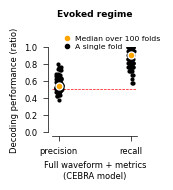

In [7]:
df_loaded = pd.read_excel("figures/8_source_data/supp_fig5d/supp_fig5d.xlsx")
fig, ax = plot_source_data(df_loaded)